# AR(3): apply inverse radial projection at every descent step

**Follow-up clarification:** the intended algorithm tracks coefficients whenever the existing sphere descent finds a new best width. That version is implemented in [ar3_best_coefficient_tracking.ipynb](ar3_best_coefficient_tracking.ipynb). This notebook retains the separate experiment with different update geometries.

Keep the **original unit-direction empirical width** throughout. Compare:

1. **Sphere:** the existing projected tangent subgradient update.
2. **Sphere expressed in φ:** take that sphere step and recover φ at *every* iteration. This is a coordinate change of method 1.
3. **Euclidean φ:** update the coefficients with the gradient of the *same normalized objective* in ordinary coefficient coordinates.

Use the fixed AR(3) example from [ar3_single_path_geometric_descent.ipynb](ar3_single_path_geometric_descent.ipynb), with true coefficients (0.5, −0.2, 0.1), T=1000, process seed 20261018 and 1000 discarded burn-in observations. Compare the earlier random direction and φ=0, with matched starting directions for all methods. True coefficients are used only for diagnostic errors after fitting. Every displayed figure is saved as PDF and PNG.

Implementation: [coefficient_descent.py](ar_tools/coefficient_descent.py), [original sphere optimizer](ar_tools/descent.py), [simulator and embedding](ar_tools/functions.py). Results describe this single path; they are not a claim about statistical performance across AR processes.

In [1]:
import json
import sys
from pathlib import Path
from time import perf_counter

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display
from threadpoolctl import threadpool_limits

AR_DIR = next(candidate.resolve()
    for root in (Path.cwd(), *Path.cwd().parents)
    for candidate in (root / 'Code' / 'Code_AR_processes', root)
    if (candidate / 'ar_tools/functions.py').is_file())
PROJECT_ROOT = AR_DIR.parents[1]
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))
from Code.Code_AR_processes.ar_tools.functions import (
    is_stationary, simulate_uniform_ar, sliding_window_point_cloud,
)
from Code.Code_AR_processes.ar_tools.descent import projected_subgradient_empirical_width
from Code.Code_AR_processes.ar_tools.coefficient_descent import (
    coefficient_width_descent, direction_from_coefficients,
    normalized_width_value_gradient,
)
from Code.Code_AR_processes.ar_tools.lp_widths import exact_empirical_width_low_dimension

EXPERIMENT = 'ar3_coefficient_space_descent'
DATA_DIR = AR_DIR / 'outputs/csv' / EXPERIMENT
PDF_DIR = AR_DIR / 'outputs/pdfs' / EXPERIMENT
IMAGE_DIR = AR_DIR / 'outputs/images' / EXPERIMENT
for directory in (DATA_DIR, PDF_DIR, IMAGE_DIR):
    directory.mkdir(parents=True, exist_ok=True)
np.set_printoptions(precision=8, suppress=True)

# All displayed figures pass through this PDF + PNG export helper.
def save_and_display(fig, stem):
    fig.savefig(PDF_DIR / f'{stem}.pdf', bbox_inches='tight')
    fig.savefig(IMAGE_DIR / f'{stem}.png', dpi=155, bbox_inches='tight')
    plt.close(fig)
    display(Image(filename=str(IMAGE_DIR / f'{stem}.png')))

Matplotlib created a temporary cache directory at /var/folders/tr/kt47kz8d61ngpcfl5d_s9fc80000gn/T/matplotlib-zuu0kzp2 because the default path (/Users/iljasukhanov/.matplotlib) is not a writable directory; it is highly recommended to set the MPLCONFIGDIR environment variable to a writable directory, in particular to speed up the import of Matplotlib and to better support multiprocessing.
Matplotlib is building the font cache; this may take a moment.


## The objective and the two coefficient updates

For newest-first windows $z_i=(y_i,x_i^\top)$, define
$$u(\phi)=\frac{(1,-\phi)}{s},\quad s=\sqrt{1+\|\phi\|^2},\qquad
R(\phi)=\max_i(y_i-x_i^\top\phi)-\min_i(y_i-x_i^\top\phi).$$
Our substitution into the original width gives
$$F(\phi)=w_P(u(\phi))=\frac{R(\phi)}{\sqrt{1+\|\phi\|^2}}.$$
**The denominator is retained.** This experiment does not optimize the unnormalized residual span.

Let $i_+,i_-$ attain the current maximum and minimum and put $g=z_{i_+}-z_{i_-}$. Our differentiation of this active branch gives
$$h(\phi)=\nabla_\phi F(\phi)=-\frac{g_{1:p}}{s}-\frac{R(\phi)\phi}{s^3}.$$
The Euclidean coefficient update is $\phi^+=\phi-\eta h(\phi)$. At unique extrema this is the ordinary gradient. At ties the implementation chooses an active branch gradient; $F$ is a finite maximum of smooth normalized pairwise residual differences. Convex subgradient rules apply to $R$, while the normalized $F$ is generally nonconvex. Sources for the max/affine rules and the nonsmooth interpretation: Boyd et al., [*Subgradients* (2022), §§3.3–3.4, p. 7; §5, pp. 10–12](https://stanford.edu/class/ee364b/lectures/subgradients_notes.pdf). The displayed formulas are our derivation for this experiment.

For the original sphere step $v=u-\eta(g-(u^\top g)u)$, applying inverse radial projection *at each step* gives
$$\phi^+=-\frac{v_{1:p}}{v_0}
=\frac{(1+\eta F)\phi+\eta s\,g_{1:p}}{(1+\eta F)-\eta s\,g_0}.$$
Thus this update describes the original sphere algorithm in coefficient coordinates wherever $v_0\ne0$. It does not define a new optimization geometry. Ordinary Euclidean descent in φ is a different step for the same objective. The implementation stops explicitly at a coefficient-chart pole; it does not clip the denominator or constrain φ to the stationary region. These statements follow from the displayed algebra and [the implementation](ar_tools/coefficient_descent.py).

In [2]:
TRUE_PHI = np.array([0.5, -0.2, 0.1])
T, BURNIN = 1000, 1000
PROCESS_SEED, OPTIMIZER_SEED = 20261018, 20261019
ITERATIONS = 5000
FIXED_GAMMA0, FIXED_BETA = 0.1, 0.997
GAMMA0_GRID = np.array([0.003, 0.01, 0.03, 0.1, 0.3])
BETA_GRID = np.array([0.65, 0.75, 0.90, 0.95, 0.97, 0.99, 0.995, 0.997, 0.999])

stationary, eigenvalues = is_stationary(TRUE_PHI)
assert stationary
series = simulate_uniform_ar(TRUE_PHI, T, burnin=BURNIN, rng=PROCESS_SEED)
points = sliding_window_point_cloud(series, 4)
assert points.shape == (T - 3, 4)
pd.DataFrame({'time': np.arange(1, T+1), 'X_t': series}).to_csv(DATA_DIR / 'process.csv', index=False)

random_u = np.random.default_rng(OPTIMIZER_SEED).normal(size=4)
random_u /= np.linalg.norm(random_u)
INITIAL_COEFFICIENTS = {
    'Earlier random direction': -random_u[1:] / random_u[0],
    'Zero coefficients': np.zeros(3),
}
with threadpool_limits(limits=1):
    global_width, global_direction, hull_vertices = exact_empirical_width_low_dimension(points)
global_phi = -global_direction[1:] / global_direction[0]
np.testing.assert_allclose(np.ptp(points @ global_direction), global_width, atol=1e-12)
configuration = {
    'T': T, 'burnin': BURNIN, 'true_phi': TRUE_PHI.tolist(),
    'process_seed': PROCESS_SEED, 'optimizer_seed': OPTIMIZER_SEED,
    'iterations': ITERATIONS, 'patience': 'disabled', 'improvement_tolerance': 0.0,
    'fixed_gamma0': FIXED_GAMMA0, 'fixed_beta': FIXED_BETA,
    'gamma0_grid': GAMMA0_GRID.tolist(), 'beta_grid': BETA_GRID.tolist(),
    'initial_coefficients': {k: v.tolist() for k,v in INITIAL_COEFFICIENTS.items()},
    'objective': 'F(phi) = residual_span(phi) / sqrt(1 + ||phi||^2)',
    'selection': 'smallest attained original width, separately for each method and start',
    'stationarity_constraint': False,
    'global_width': global_width, 'global_phi': global_phi.tolist(),
    'global_reference_method': 'floating-point difference-body convex hull in dimension four',
}
(DATA_DIR / 'configuration.json').write_text(json.dumps(configuration, indent=2) + '\n')
print(f'Companion spectral radius: {np.max(abs(eigenvalues)):.8f}')
print(f'Floating-point global empirical width reference: {global_width:.12f}')
print(f'Coefficients of that empirical minimizer: {global_phi}')
for label, phi0 in INITIAL_COEFFICIENTS.items():
    print(f'{label}: phi0 = {phi0}; u0 = {direction_from_coefficients(phi0)[0]:.8f}')

Companion spectral radius: 0.50000000
Floating-point global empirical width reference: 1.747611555746
Coefficients of that empirical minimizer: [ 0.50066818 -0.20307294  0.10251497]
Earlier random direction: phi0 = [ 17.30249735  -6.66938892 -10.4730856 ]; u0 = 0.04690430
Zero coefficients: phi0 = [0. 0. 0.]; u0 = 1.00000000


## Same-schedule comparison

All three methods use the literal schedule $\eta_t=0.1(0.997)^t$, 5000 evaluated states and no patience stopping. The sphere baseline calls the existing optimizer; optional direction recording does not alter its updates. Best states are chosen only by original empirical width. A state is evaluated before its next step, matching the original optimizer.

The global reference is recomputed on the same cloud with [exact_empirical_width_low_dimension](ar_tools/lp_widths.py). It is a floating-point hull calculation, not an exact-arithmetic certificate. Coefficient errors below are diagnostics relative to the generating vector, not optimization criteria.

In [3]:
METHODS = ['Sphere', 'Sphere expressed in phi', 'Euclidean phi']
COLORS = {'Sphere': '#315a9a', 'Sphere expressed in phi': '#2a8c7b', 'Euclidean phi': '#d55e00'}

def fit(method, phi0, gamma0, beta, record=True):
    started = perf_counter()
    if method == 'Sphere':
        result = projected_subgradient_empirical_width(
            points, iterations=ITERATIONS, initial_step=gamma0,
            patience=ITERATIONS+1, improvement_tolerance=0.0,
            initial_direction=direction_from_coefficients(phi0),
            step_schedule='geometric', geometric_decay=beta, record_directions=record,
        )
        result['coefficients'] = -result['direction'][1:] / result['direction'][0]
        result['evaluations'] = len(result['width_history'])
        if record:
            directions = result['direction_history']
            if np.any(np.abs(directions[:, 0]) <= np.finfo(float).eps):
                raise FloatingPointError('A recorded sphere state lies at a coefficient-chart pole.')
            result['coefficient_history'] = -directions[:, 1:] / directions[:, :1]
    else:
        result = coefficient_width_descent(
            points, phi0, iterations=ITERATIONS, initial_step=gamma0,
            geometric_decay=beta, geometry='sphere' if method == 'Sphere expressed in phi' else 'euclidean',
            record_history=record,
        )
    result['runtime_seconds'] = perf_counter() - started
    return result

def row_for(start_label, method, result, gamma0, beta):
    phi = result['coefficients']
    physical_width = float(np.ptp(points @ result['direction']))
    np.testing.assert_allclose(physical_width, result['minimum_width'], atol=1e-12, rtol=0)
    assert physical_width >= global_width - 1e-9
    return dict(start=start_label, method=method, gamma0=float(gamma0), beta=float(beta),
        minimum_width=physical_width, width_gap=physical_width-global_width,
        relative_gap_percent=100*(physical_width/global_width-1),
        coefficient_l2_error=float(np.linalg.norm(phi-TRUE_PHI)),
        phi_1=float(phi[0]), phi_2=float(phi[1]), phi_3=float(phi[2]),
        stationary=is_stationary(phi)[0], evaluations=result['evaluations'],
        termination_reason=result['termination_reason'], runtime_seconds=result['runtime_seconds'])

def history_for(start_label, method, result):
    coefficients = result['coefficient_history']
    values = result['width_history']
    # Select diagnostic coefficients by attained objective, never by true error.
    indices = np.where(np.r_[True, np.diff(result['best_width_history']) < 0], np.arange(len(values)), 0)
    best_indices = np.maximum.accumulate(indices)
    frame = pd.DataFrame({
        'start': start_label, 'method': method, 'iteration': np.arange(len(values)),
        'current_width': values, 'best_width': result['best_width_history'],
        'step': result['step_history'],
        'best_width_coefficient_l2_error': np.linalg.norm(coefficients[best_indices] - TRUE_PHI, axis=1),
        'phi_1': coefficients[:,0], 'phi_2': coefficients[:,1], 'phi_3': coefficients[:,2],
        'abs_u0': 1/np.hypot.reduce(np.column_stack([np.ones(len(values)), coefficients]), axis=1),
    })
    return frame

fixed_fits, fixed_rows, fixed_histories = {}, [], []
with threadpool_limits(limits=1):
    for start_label, phi0 in INITIAL_COEFFICIENTS.items():
        for method in METHODS:
            result = fit(method, phi0, FIXED_GAMMA0, FIXED_BETA)
            assert result['evaluations'] == ITERATIONS
            fixed_fits[start_label, method] = result
            fixed_rows.append(row_for(start_label, method, result, FIXED_GAMMA0, FIXED_BETA))
            fixed_histories.append(history_for(start_label, method, result))
fixed_results = pd.DataFrame(fixed_rows)
fixed_history = pd.concat(fixed_histories, ignore_index=True)
fixed_results.to_csv(DATA_DIR / 'fixed_schedule_results.csv', index=False)
fixed_history.to_csv(DATA_DIR / 'fixed_schedule_histories.csv', index=False)
display(fixed_results[['start','method','minimum_width','relative_gap_percent','coefficient_l2_error','stationary']])

# Independent round-trip identity at every recorded baseline state. Width is even:
# the positive-u0 representative can flip the sign of a sphere direction.
roundtrip_rows = []
for start_label in INITIAL_COEFFICIENTS:
    baseline = fixed_fits[start_label, 'Sphere']
    directions = baseline['direction_history']
    phis = baseline['coefficient_history']
    recovered = np.column_stack([np.ones(len(phis)), -phis])
    recovered /= np.linalg.norm(recovered, axis=1, keepdims=True)
    canonical = directions * np.sign(directions[:, :1])
    roundtrip_error = float(np.max(np.linalg.norm(recovered-canonical, axis=1)))
    assert roundtrip_error < 2e-14
    mapped = fixed_fits[start_label, 'Sphere expressed in phi']
    roundtrip_rows.append(dict(start=start_label, maximum_projective_roundtrip_error=roundtrip_error,
        best_width_difference=float(mapped['minimum_width']-baseline['minimum_width']),
        maximum_full_run_width_difference=float(np.max(abs(mapped['width_history']-baseline['width_history'])))))
roundtrip_results = pd.DataFrame(roundtrip_rows)
roundtrip_results.to_csv(DATA_DIR / 'coordinate_equivalence_checks.csv', index=False)
display(roundtrip_results)
print('Independent full runs can separate at active-set ties because of floating-point roundoff; final best widths and full-run discrepancies are reported separately.')

Independent full runs can separate at active-set ties because of floating-point roundoff; final best widths and full-run discrepancies are reported separately.


,start,method,minimum_width,relative_gap_percent,coefficient_l2_error,stationary
0,Earlier random direction,Sphere,1.862952,6.599915e+00,30.578110,False
1,Earlier random direction,Sphere expressed in phi,1.862952,6.599915e+00,30.578108,False
2,Earlier random direction,Euclidean phi,2.808545,6.070765e+01,20.832098,False
3,Zero coefficients,Sphere,1.747612,4.704631e-07,0.004027,True
4,Zero coefficients,Sphere expressed in phi,1.747612,5.512659e-07,0.004027,True
5,Zero coefficients,Euclidean phi,1.747612,3.379715e-07,0.004027,True


,start,maximum_projective_roundtrip_error,best_width_difference,maximum_full_run_width_difference
0,Earlier random direction,3.522471e-16,2.077227e-12,0.128637
1,Zero coefficients,3.775166e-16,1.412119e-09,0.199377


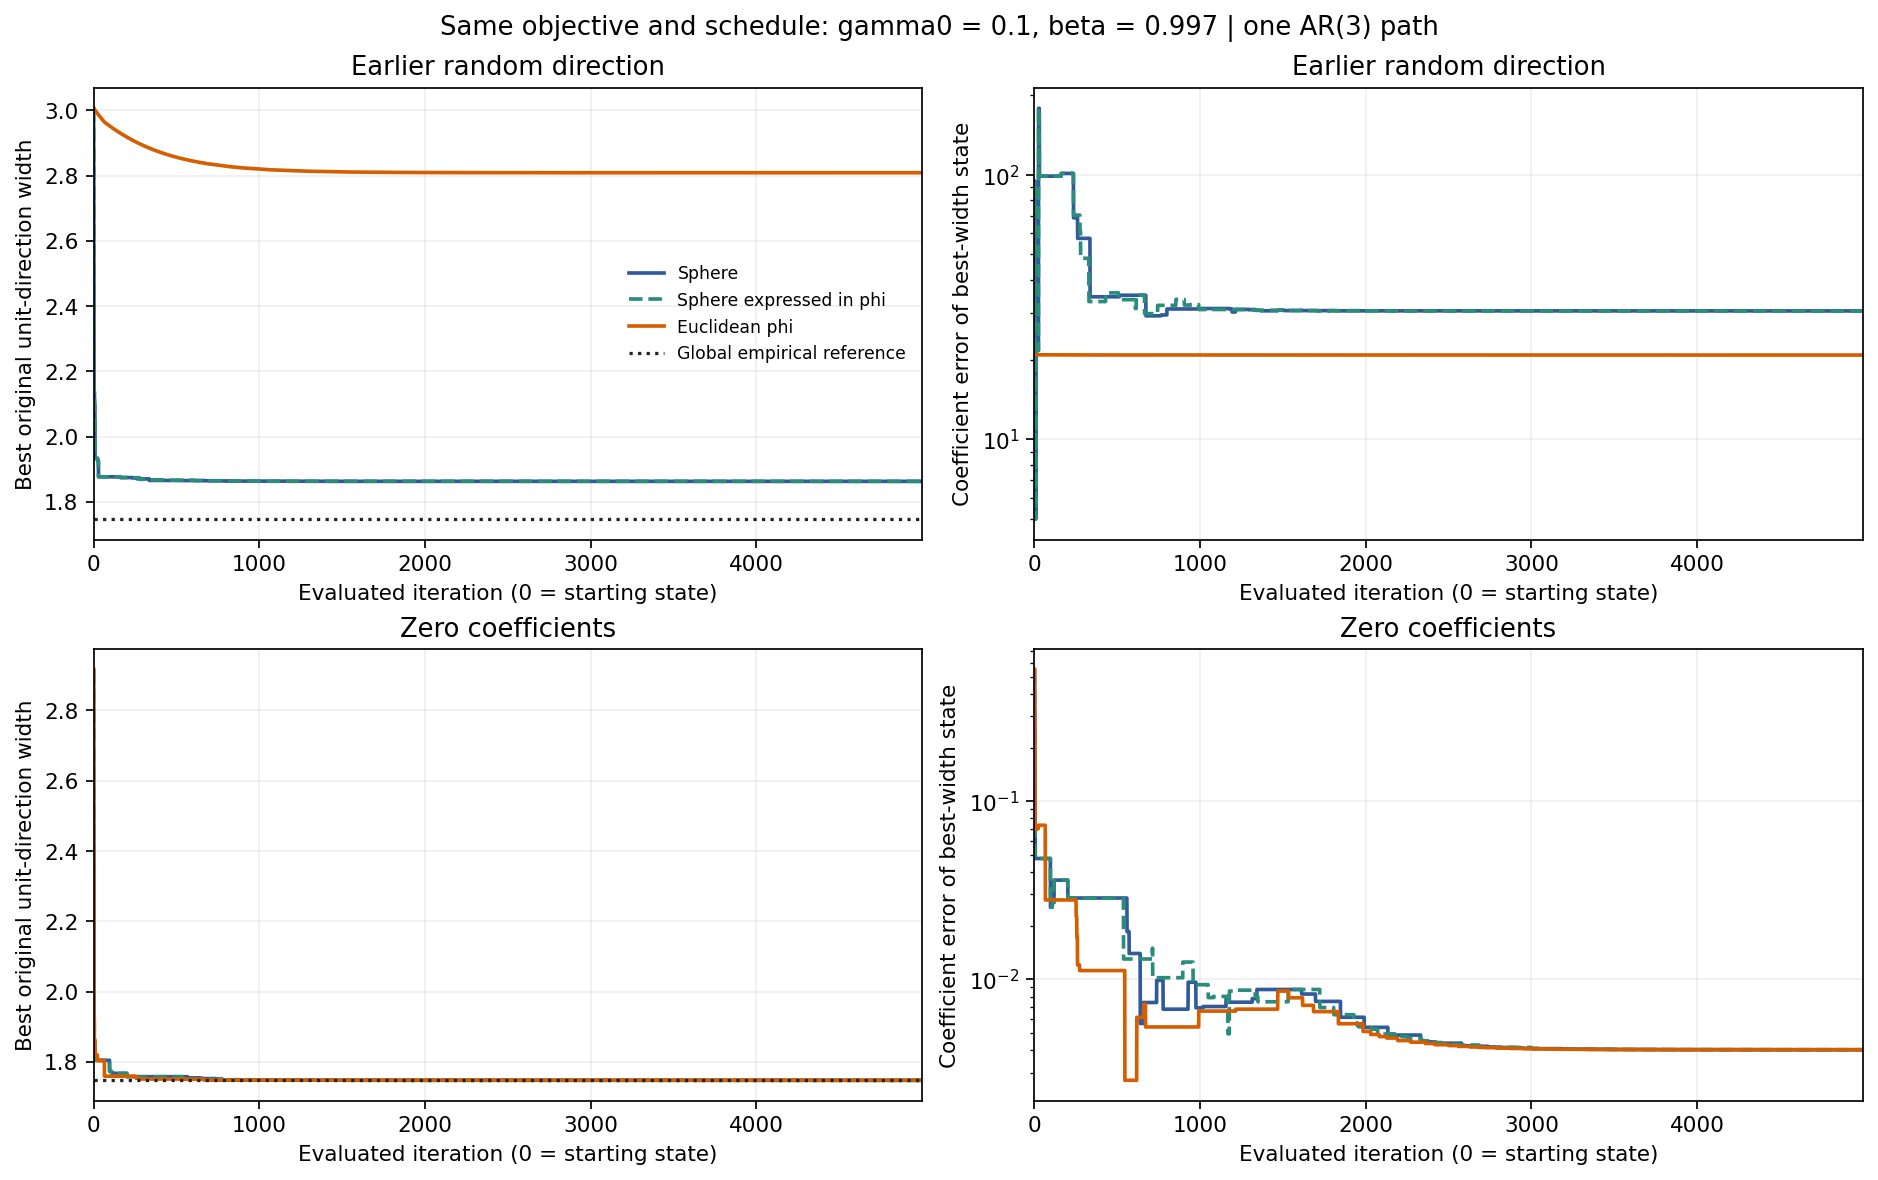

In [4]:
with plt.rc_context({'font.size': 10, 'pdf.fonttype': 42}):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), constrained_layout=True)
    for i, start_label in enumerate(INITIAL_COEFFICIENTS):
        for method in METHODS:
            frame = fixed_history[(fixed_history.start == start_label) & (fixed_history.method == method)]
            style = '--' if method == 'Sphere expressed in phi' else '-'
            axes[i,0].plot(frame.iteration, frame.best_width, style, color=COLORS[method], label=method, lw=1.7)
            axes[i,1].plot(frame.iteration, frame.best_width_coefficient_l2_error,
                           style, color=COLORS[method], label=method, lw=1.7)
        axes[i,0].axhline(global_width, color='#222222', ls=':', label='Global empirical reference')
        axes[i,0].set(ylabel='Best original unit-direction width', title=start_label)
        axes[i,1].set(ylabel='Coefficient error of best-width state', yscale='log', title=start_label)
        for ax in axes[i]:
            ax.set(xlabel='Evaluated iteration (0 = starting state)', xlim=(0, ITERATIONS-1))
            ax.grid(alpha=.2)
    axes[0,0].legend(fontsize=8, frameon=False)
    fig.suptitle('Same objective and schedule: gamma0 = 0.1, beta = 0.997 | one AR(3) path')
    save_and_display(fig, '01_same_schedule_comparison')

## Common schedule grid, selected by the original width

Compare 45 $(\eta_0,\beta)$ pairs for each of the two distinct update geometries and each starting point. Every pair receives the same 5000-state budget on the same path. The grid uses the values from the earlier single-path notebook. The coordinate-only sphere version is already checked above; it needs no independent tuning grid.

Select each method's schedule using only its smallest achieved original width. This is an optimization comparison on one cloud, not validation on new time series. The ordinary φ gradient and sphere tangent gradient have different scales, so the common grid is a transparent budget comparison rather than a complete tuning guarantee.

In [5]:
grid_rows = []
with threadpool_limits(limits=1):
    for start_label, phi0 in INITIAL_COEFFICIENTS.items():
        for method in ['Sphere', 'Euclidean phi']:
            for gamma0 in GAMMA0_GRID:
                for beta in BETA_GRID:
                    result = fit(method, phi0, float(gamma0), float(beta), record=False)
                    assert result['evaluations'] == ITERATIONS
                    grid_rows.append(row_for(start_label, method, result, gamma0, beta))
            print(f'Completed 45 schedules: {start_label}; {method}', flush=True)
grid_results = pd.DataFrame(grid_rows)
assert len(grid_results) == 180
grid_results.to_csv(DATA_DIR / 'schedule_grid.csv', index=False)
selected_rows = grid_results.loc[grid_results.groupby(['start','method'], sort=False).minimum_width.idxmin()].copy()
selected_rows['selection_on_grid_edge'] = (
    selected_rows.gamma0.isin([GAMMA0_GRID.min(), GAMMA0_GRID.max()])
    | selected_rows.beta.isin([BETA_GRID.min(), BETA_GRID.max()])
)
selected_rows.to_csv(DATA_DIR / 'selected_results.csv', index=False)
selected_fits, selected_histories = {}, []
with threadpool_limits(limits=1):
    for row in selected_rows.itertuples():
        result = fit(row.method, INITIAL_COEFFICIENTS[row.start], row.gamma0, row.beta)
        np.testing.assert_allclose(result['minimum_width'], row.minimum_width, rtol=0, atol=1e-12)
        selected_fits[row.start, row.method] = result
        selected_histories.append(history_for(row.start, row.method, result))
selected_history = pd.concat(selected_histories, ignore_index=True)
selected_history.to_csv(DATA_DIR / 'selected_histories.csv', index=False)
display(selected_rows[['start','method','gamma0','beta','minimum_width','relative_gap_percent',
                       'phi_1','phi_2','phi_3','coefficient_l2_error','selection_on_grid_edge']])

Completed 45 schedules: Earlier random direction; Sphere
Completed 45 schedules: Earlier random direction; Euclidean phi
Completed 45 schedules: Zero coefficients; Sphere
Completed 45 schedules: Zero coefficients; Euclidean phi


,start,method,gamma0,beta,minimum_width,relative_gap_percent,phi_1,phi_2,phi_3,coefficient_l2_error,selection_on_grid_edge
23,Earlier random direction,Sphere,0.030,0.990,1.862952,6.599915e+00,27.493001,-14.014124,4.045697,30.578107,False
89,Earlier random direction,Euclidean phi,0.300,0.999,1.873969,7.230299e+00,18.956945,-9.599584,2.691280,20.874044,True
96,Zero coefficients,Sphere,0.003,0.995,1.747612,6.439294e-13,0.500668,-0.203073,0.102515,0.004027,True
141,Zero coefficients,Euclidean phi,0.003,0.995,1.747612,4.440892e-13,0.500668,-0.203073,0.102515,0.004027,True


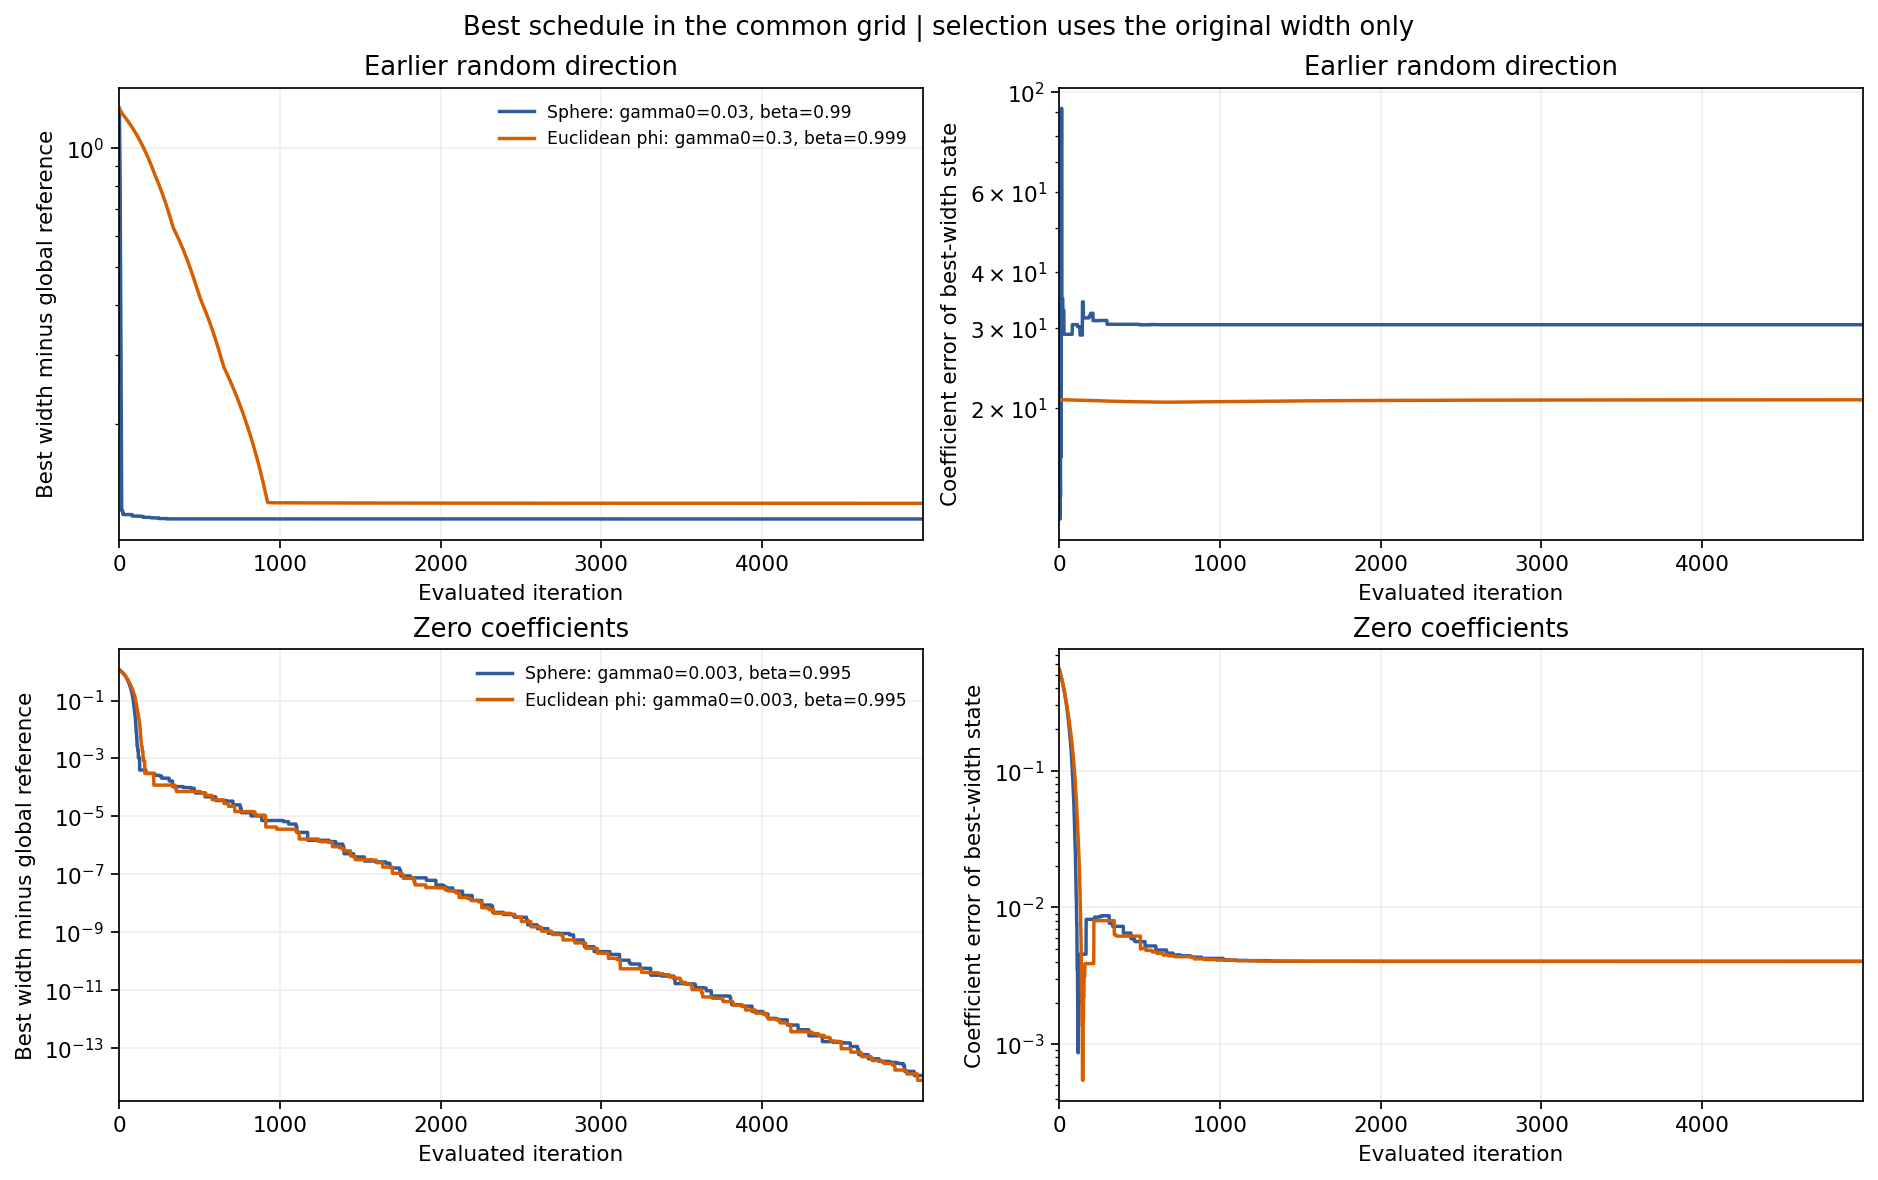

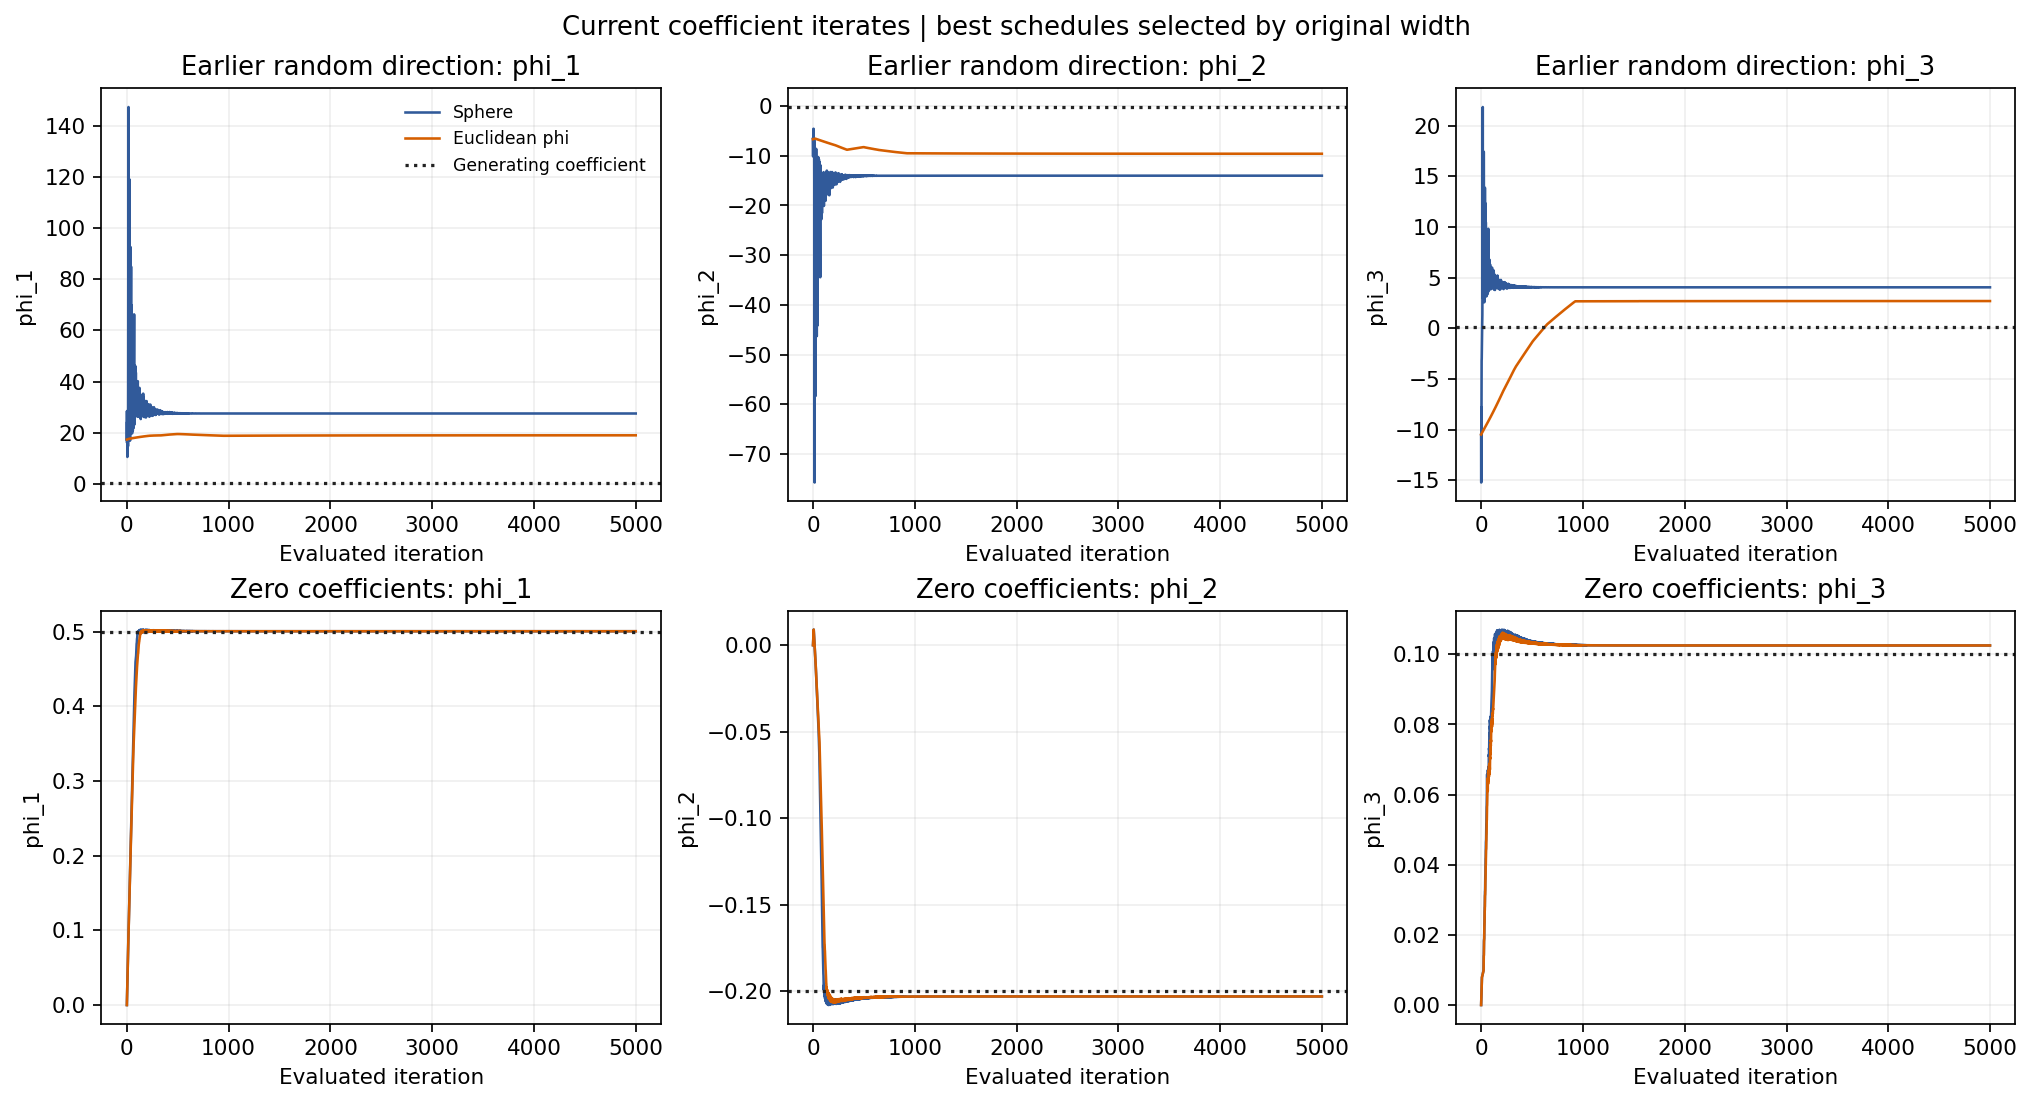

In [6]:
with plt.rc_context({'font.size': 10, 'pdf.fonttype': 42}):
    fig, axes = plt.subplots(2, 2, figsize=(12, 7.5), constrained_layout=True)
    for i, start_label in enumerate(INITIAL_COEFFICIENTS):
        for method in ['Sphere', 'Euclidean phi']:
            frame = selected_history[(selected_history.start == start_label) & (selected_history.method == method)]
            selected = selected_rows[(selected_rows.start == start_label) & (selected_rows.method == method)].iloc[0]
            label = f'{method}: gamma0={selected.gamma0:g}, beta={selected.beta:g}'
            gap = np.maximum(frame.best_width.to_numpy()-global_width, 1e-15)
            axes[i,0].semilogy(frame.iteration, gap, color=COLORS[method], lw=1.6, label=label)
            axes[i,1].semilogy(frame.iteration, frame.best_width_coefficient_l2_error,
                               color=COLORS[method], lw=1.6, label=method)
        axes[i,0].set(ylabel='Best width minus global reference', title=start_label)
        axes[i,1].set(ylabel='Coefficient error of best-width state', title=start_label)
        axes[i,0].legend(fontsize=8, frameon=False)
        for ax in axes[i]:
            ax.set(xlabel='Evaluated iteration', xlim=(0, ITERATIONS-1))
            ax.grid(alpha=.2)
    fig.suptitle('Best schedule in the common grid | selection uses the original width only')
    save_and_display(fig, '02_selected_schedule_comparison')

with plt.rc_context({'font.size': 10, 'pdf.fonttype': 42}):
    fig, axes = plt.subplots(2, 3, figsize=(13, 7), constrained_layout=True)
    for i, start_label in enumerate(INITIAL_COEFFICIENTS):
        for j in range(3):
            for method in ['Sphere', 'Euclidean phi']:
                frame = selected_history[(selected_history.start == start_label) & (selected_history.method == method)]
                axes[i,j].plot(frame.iteration, frame[f'phi_{j+1}'], color=COLORS[method], label=method, lw=1.2)
            axes[i,j].axhline(TRUE_PHI[j], ls=':', color='#222222', label='Generating coefficient')
            axes[i,j].set(xlabel='Evaluated iteration', ylabel=f'phi_{j+1}', title=f'{start_label}: phi_{j+1}')
            axes[i,j].grid(alpha=.2)
    axes[0,0].legend(fontsize=8, frameon=False)
    fig.suptitle('Current coefficient iterates | best schedules selected by original width')
    save_and_display(fig, '03_coefficient_trajectories')

## Interpretation and reproducibility

The final cell writes the attained results and a short findings report. Converting each sphere iterate to φ and back is algebraically the same sphere method wherever the chart exists. Ordinary φ descent retains the objective but changes the step geometry, which is the substantive alternative tested here.

The chart excludes $u_0=0$ and sends directions with small $|u_0|$ to large coefficients. That follows directly from $\phi=-u_{1:p}/u_0$. The two chosen starts make this sensitivity visible without changing the AR process. Reaching the global empirical width is distinct from recovering the generating coefficients exactly; both quantities are reported separately.

All generated data and figures are stored under this notebook's name in `outputs/csv`, `outputs/pdfs` and `outputs/images`. No thesis files are modified. Further inference across AR processes or starting directions would require additional experiments.

In [7]:
from IPython.display import Markdown

def result_table(frame):
    lines = ['| Starting point | Method | gamma0 | beta | Width | Gap to global reference | Coefficient error |',
             '|---|---|---:|---:|---:|---:|---:|']
    for row in frame.itertuples():
        lines.append(f'| {row.start} | {row.method} | {row.gamma0:g} | {row.beta:g} | '
                     f'{row.minimum_width:.10f} | {row.relative_gap_percent:.6g}% | '
                     f'{row.coefficient_l2_error:.8f} |')
    return '\n'.join(lines)

zero = selected_rows[selected_rows.start == 'Zero coefficients']
random = selected_rows[selected_rows.start == 'Earlier random direction']
zero_phi = zero[zero.method == 'Euclidean phi'].iloc[0][['phi_1','phi_2','phi_3']].to_numpy(dtype=float)
random_sphere = random[random.method == 'Sphere'].iloc[0]
random_euclidean = random[random.method == 'Euclidean phi'].iloc[0]

report = [
    '# Coefficient-space descent on the original AR(3) width',
    'This is our derivation and numerical experiment on one fixed path.',
    f'Process: phi={TRUE_PHI.tolist()}, T={T}, burn-in={BURNIN}, innovations Uniform[-1,1], process seed={PROCESS_SEED}.',
    '**Finding:** the tested Euclidean coefficient updates do not improve the attained original width in this example. '
    f'From zero, both methods reach the floating-point global reference to within {zero.width_gap.max():.2g}. '
    f'The recovered coefficients are approximately ({zero_phi[0]:.8f}, {zero_phi[1]:.8f}, {zero_phi[2]:.8f}). '
    f'From the earlier random direction, the best grid gaps are {random_sphere.relative_gap_percent:.4f}% for sphere descent '
    f'and {random_euclidean.relative_gap_percent:.4f}% for Euclidean coefficient descent.',
    '## Objective and update',
    'The objective always retains its denominator: F(phi)=range(y-X phi)/sqrt(1+||phi||^2). '
    'Applying inverse radial projection to every sphere step is algebraically a change of coordinates. '
    'Ordinary Euclidean phi descent changes the step geometry while keeping this same objective. '
    'The derivation and both updates are in [the notebook, "The objective and the two coefficient updates"](../../../ar3_coefficient_space_descent.ipynb) '
    'and [coefficient_descent.py](../../../ar_tools/coefficient_descent.py).',
    f'Global empirical width reference (floating-point difference-body hull): {global_width:.12f}; '
    f'associated coefficients: {global_phi.tolist()}. Implementation: [lp_widths.py](../../../ar_tools/lp_widths.py), exact_empirical_width_low_dimension.',
    '## Same schedule: gamma0=0.1, beta=0.997, 5000 evaluated states',
    result_table(fixed_results),
    '## Best of 45 schedules per method and starting point',
    result_table(selected_rows),
    'Each pair uses the same 5000-state budget. Selection uses only the original width; generating coefficients are used only for diagnostic errors. '
    'Sources: [schedule grid](schedule_grid.csv), [selected results](selected_results.csv), [configuration](configuration.json).',
    '## Coordinate check',
    f'The largest projective round-trip error is {roundtrip_results.maximum_projective_roundtrip_error.max():.3g}. '
    f'For independently run sphere and mapped-sphere updates, the largest difference between best widths is '
    f'{roundtrip_results.best_width_difference.abs().max():.3g}. '
    f'The largest discrepancy between current widths along these full numerical trajectories is '
    f'{roundtrip_results.maximum_full_run_width_difference.max():.6f}; '
    'active-set switches can separate floating-point trajectories despite the algebraic coordinate equivalence. '
    'Source: [coordinate equivalence checks](coordinate_equivalence_checks.csv).',
    '## Limits',
    'One fixed path, two starting points, geometric steps and a finite grid. A grid-edge winner leaves room for further tuning. '
    'Failure of these coefficient schedules does not exclude better schedules or other processes. '
    'The coefficient chart excludes u0=0, and small |u0| gives large initial coefficients. '
    'The earlier random start has |u0|=0.04690430 and phi0 approximately (17.3025,-6.6694,-10.4731). '
    'No stationarity constraint is imposed on the estimates. '
    'These limitations follow from the settings, coordinate formulas, and saved runs; they are not a general impossibility result.',
    '## Sources',
    '- Boyd, Duchi, Pilanci and Vandenberghe, [Subgradients (2022), sections 3.3–3.4, p. 7, and section 5, pp. 10–12](https://stanford.edu/class/ee364b/lectures/subgradients_notes.pdf): '
    'affine/max subgradient rules and the generalized-gradient interpretation. The experiment-specific substitution and gradient formulas are our derivation.',
    '- [Original sphere optimizer](../../../ar_tools/descent.py), projected_subgradient_empirical_width; '
    '[simulator and newest-first embedding](../../../ar_tools/functions.py), simulate_uniform_ar and sliding_window_point_cloud.',
]
report_text = '\n\n'.join(report) + '\n'
(DATA_DIR / 'findings.md').write_text(report_text)
summary = dict(configuration, fixed_results=fixed_results.to_dict(orient='records'),
               selected_results=selected_rows.to_dict(orient='records'),
               coordinate_checks=roundtrip_results.to_dict(orient='records'))
(DATA_DIR / 'summary.json').write_text(json.dumps(summary, indent=2) + '\n')
display(Markdown(report_text))
print(f'PDF figures: {PDF_DIR}')

PDF figures: /Users/iljasukhanov/MASTERARBEIT/Code/Code_AR_processes/outputs/pdfs/ar3_coefficient_space_descent


# Coefficient-space descent on the original AR(3) width

This is our derivation and numerical experiment on one fixed path.

Process: phi=[0.5, -0.2, 0.1], T=1000, burn-in=1000, innovations Uniform[-1,1], process seed=20261018.

**Finding:** the tested Euclidean coefficient updates do not improve the attained original width in this example. From zero, both methods reach the floating-point global reference to within 1.1e-14. The recovered coefficients are approximately (0.50066818, -0.20307294, 0.10251497). From the earlier random direction, the best grid gaps are 6.5999% for sphere descent and 7.2303% for Euclidean coefficient descent.

## Objective and update

The objective always retains its denominator: F(phi)=range(y-X phi)/sqrt(1+||phi||^2). Applying inverse radial projection to every sphere step is algebraically a change of coordinates. Ordinary Euclidean phi descent changes the step geometry while keeping this same objective. The derivation and both updates are in [the notebook, "The objective and the two coefficient updates"](../../../ar3_coefficient_space_descent.ipynb) and [coefficient_descent.py](../../../ar_tools/coefficient_descent.py).

Global empirical width reference (floating-point difference-body hull): 1.747611555746; associated coefficients: [0.5006681806450801, -0.2030729406195368, 0.10251496982549076]. Implementation: [lp_widths.py](../../../ar_tools/lp_widths.py), exact_empirical_width_low_dimension.

## Same schedule: gamma0=0.1, beta=0.997, 5000 evaluated states

| Starting point | Method | gamma0 | beta | Width | Gap to global reference | Coefficient error |
|---|---|---:|---:|---:|---:|---:|
| Earlier random direction | Sphere | 0.1 | 0.997 | 1.8629524383 | 6.59992% | 30.57811049 |
| Earlier random direction | Sphere expressed in phi | 0.1 | 0.997 | 1.8629524383 | 6.59992% | 30.57810801 |
| Earlier random direction | Euclidean phi | 0.1 | 0.997 | 2.8085454894 | 60.7077% | 20.83209791 |
| Zero coefficients | Sphere | 0.1 | 0.997 | 1.7476115640 | 4.70463e-07% | 0.00402689 |
| Zero coefficients | Sphere expressed in phi | 0.1 | 0.997 | 1.7476115654 | 5.51266e-07% | 0.00402689 |
| Zero coefficients | Euclidean phi | 0.1 | 0.997 | 1.7476115617 | 3.37971e-07% | 0.00402686 |

## Best of 45 schedules per method and starting point

| Starting point | Method | gamma0 | beta | Width | Gap to global reference | Coefficient error |
|---|---|---:|---:|---:|---:|---:|
| Earlier random direction | Sphere | 0.03 | 0.99 | 1.8629524361 | 6.59992% | 30.57810746 |
| Earlier random direction | Euclidean phi | 0.3 | 0.999 | 1.8739691010 | 7.2303% | 20.87404433 |
| Zero coefficients | Sphere | 0.003 | 0.995 | 1.7476115557 | 6.43929e-13% | 0.00402672 |
| Zero coefficients | Euclidean phi | 0.003 | 0.995 | 1.7476115557 | 4.44089e-13% | 0.00402672 |

Each pair uses the same 5000-state budget. Selection uses only the original width; generating coefficients are used only for diagnostic errors. Sources: [schedule grid](schedule_grid.csv), [selected results](selected_results.csv), [configuration](configuration.json).

## Coordinate check

The largest projective round-trip error is 3.78e-16. For independently run sphere and mapped-sphere updates, the largest difference between best widths is 1.41e-09. The largest discrepancy between current widths along these full numerical trajectories is 0.199377; active-set switches can separate floating-point trajectories despite the algebraic coordinate equivalence. Source: [coordinate equivalence checks](coordinate_equivalence_checks.csv).

## Limits

One fixed path, two starting points, geometric steps and a finite grid. A grid-edge winner leaves room for further tuning. Failure of these coefficient schedules does not exclude better schedules or other processes. The coefficient chart excludes u0=0, and small |u0| gives large initial coefficients. The earlier random start has |u0|=0.04690430 and phi0 approximately (17.3025,-6.6694,-10.4731). No stationarity constraint is imposed on the estimates. These limitations follow from the settings, coordinate formulas, and saved runs; they are not a general impossibility result.

## Sources

- Boyd, Duchi, Pilanci and Vandenberghe, [Subgradients (2022), sections 3.3–3.4, p. 7, and section 5, pp. 10–12](https://stanford.edu/class/ee364b/lectures/subgradients_notes.pdf): affine/max subgradient rules and the generalized-gradient interpretation. The experiment-specific substitution and gradient formulas are our derivation.

- [Original sphere optimizer](../../../ar_tools/descent.py), projected_subgradient_empirical_width; [simulator and newest-first embedding](../../../ar_tools/functions.py), simulate_uniform_ar and sliding_window_point_cloud.
